# **TUẦN 41 — ATTENTION-GATED FUSION + UNIFASHION**


## **1 — Phát hiện phần cứng**

In [ ]:
import os
from pathlib import Path


def detect_backend():
    """Chỉ hỗ trợ GPU NVIDIA (CUDA) và không gắn cứng loại GPU"""
    info = {"backend": "none", "name": None, "vram_gib": None, "torch": None}
    try:
        import torch
    except ImportError:
        return info
    info["torch"] = torch.__version__
    if torch.cuda.is_available():
        props = torch.cuda.get_device_properties(0)
        info.update(
            backend="cuda",
            name=props.name,
            vram_gib=round(props.total_memory / 2**30, 1),
            capability=f"{props.major}.{props.minor}",
        )
    return info


HW = detect_backend()
BACKEND = HW["backend"]
TRAIN_ENABLED = BACKEND == "cuda"   # chỉ GPU CUDA mới chạy được bước fine-tune

print("Phát hiện:", HW)
if BACKEND == "cuda":
    print(f"\nGPU: {HW['name']} | {HW['vram_gib']} GiB | compute capability {HW['capability']}")
    if HW["vram_gib"] < 14:
        print("CẢNH BÁO: VRAM < 14 GiB. Cấu hình fp32 + batch 2 đã chạy ổn trên T4 (15 GiB); "
              "GPU nhỏ hơn có thể OOM.")
    print("→ Bước fine-tune: BẬT (precision/batch lấy từ config, không phụ thuộc loại GPU).")
else:
    on_tpu = bool(os.environ.get("TPU_NAME") or os.environ.get("COLAB_TPU_ADDR")
                  or Path("/dev/accel0").exists())
    if on_tpu:
        print("\nBạn đang chọn runtime TPU. Code train của repo chỉ chạy trên GPU CUDA nên bước fine-tune sẽ bị bỏ qua.")
    else:
        print("\nRuntime hiện tại không có GPU CUDA nên bước fine-tune sẽ bị bỏ qua.")
    print("Muốn train: Runtime → Change runtime type → chọn GPU (T4 hoặc loại mạnh hơn), rồi Run all.\n"
          "Các bước chuẩn bị dữ liệu vẫn chạy được trên runtime này.")

Phát hiện: {'backend': 'cuda', 'name': 'NVIDIA L4', 'vram_gib': 22.0, 'torch': '2.11.0+cu130', 'capability': '8.9'}

GPU: NVIDIA L4 | 22.0 GiB | compute capability 8.9
→ Bước fine-tune: BẬT (precision/batch lấy từ config, không phụ thuộc loại GPU).


## **2 — Clone đúng hai repo**

In [ ]:
from pathlib import Path
import subprocess

def run(cmd):
    subprocess.run(cmd, check=True)

PROJECT = Path("/content/khoaluantotnghiep")
UPSTREAM = Path("/content/UniFashion-upstream")

if not PROJECT.exists():
    run(["git", "clone", "--branch", "hien",
         "https://github.com/okok0814/khoaluantotnghiep.git",
         str(PROJECT)])

if not UPSTREAM.exists():
    run(["git", "clone",
         "https://github.com/xiangyu-mm/UniFashion.git",
         str(UPSTREAM)])

assert (PROJECT / "scripts/train_unifashion_finetune.py").exists(), \
    "Sai repo hoặc thiếu script train."
assert (PROJECT / "src/unifashion_runtime.py").exists(), \
    "Thiếu unifashion_runtime.py."

alias = Path("/content/UniFashion")
if not alias.exists():
    alias.symlink_to(UPSTREAM, target_is_directory=True)

head = subprocess.run(["git", "-C", str(PROJECT), "rev-parse", "HEAD"],
                      capture_output=True, text=True).stdout.strip()
print("PROJECT:", PROJECT, "| HEAD:", head[:10])
print("UPSTREAM:", UPSTREAM)

PROJECT: /content/khoaluantotnghiep | HEAD: 1d64db4b87
UPSTREAM: /content/UniFashion-upstream


## **3 — Mount Google Drive**

In [ ]:
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

PROJECT_DIR = Path("/content/khoaluantotnghiep")
UPSTREAM_DIR = Path("/content/UniFashion-upstream")

DATASET_DIR = Path(
    "/content/drive/MyDrive/KHOALUAN/Tuần 37/FashionIQ/fashionIQ_dataset"
)
IMAGES_DIR = DATASET_DIR / "images"
IMAGE_SPLITS_DIR = DATASET_DIR / "image_splits"
CAPTIONS_DIR = DATASET_DIR / "captions"

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/KHOALUAN/Tuần 41/UniFashionResults"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("PROJECT_DIR:", PROJECT_DIR)
print("UPSTREAM_DIR:", UPSTREAM_DIR)
print("DATASET_DIR:", DATASET_DIR)
print("IMAGES_DIR:", IMAGES_DIR)
print("IMAGE_SPLITS_DIR:", IMAGE_SPLITS_DIR)
print("CAPTIONS_DIR:", CAPTIONS_DIR)
print("OUTPUT_DIR:", OUTPUT_DIR)

Mounted at /content/drive
PROJECT_DIR: /content/khoaluantotnghiep
UPSTREAM_DIR: /content/UniFashion-upstream
DATASET_DIR: /content/drive/MyDrive/KHOALUAN/Tuần 37/FashionIQ/fashionIQ_dataset
IMAGES_DIR: /content/drive/MyDrive/KHOALUAN/Tuần 37/FashionIQ/fashionIQ_dataset/images
IMAGE_SPLITS_DIR: /content/drive/MyDrive/KHOALUAN/Tuần 37/FashionIQ/fashionIQ_dataset/image_splits
CAPTIONS_DIR: /content/drive/MyDrive/KHOALUAN/Tuần 37/FashionIQ/fashionIQ_dataset/captions
OUTPUT_DIR: /content/drive/MyDrive/KHOALUAN/Tuần 41/UniFashionResults


## **4 — Kiểm tra checkpoint và dữ liệu**

In [ ]:
# Kiểm tra dataset không quét từng ảnh
required_dirs = {
    "dataset": DATASET_DIR,
    "images": IMAGES_DIR,
    "image_splits": IMAGE_SPLITS_DIR,
    "captions": CAPTIONS_DIR,
}

for name, path in required_dirs.items():
    print(f"{'OK' if path.is_dir() else 'MISSING'} | {name}: {path}")

missing_dirs = [
    name for name, path in required_dirs.items()
    if not path.is_dir()
]
assert not missing_dirs, f"Thiếu thư mục dataset: {missing_dirs}"

# Chỉ tìm model assets ở những vị trí đã dự kiến
ASSETS_DIR = Path("/content/drive/MyDrive/UniFashionAssets")

required_assets = [
    ASSETS_DIR / "eva_vit_g.pth",
    ASSETS_DIR / "pretrain" / "none_lora_0.pt",
    ASSETS_DIR / "bert-base-uncased",
]

print("\nMODEL ASSETS")
for path in required_assets:
    print(f"{'OK' if path.exists() else 'MISSING'} | {path}")

print("\nDataset directories PASS")
print("Nếu model assets còn MISSING thì cần sửa ASSETS_DIR trước khi train.")

OK | dataset: /content/drive/MyDrive/KHOALUAN/Tuần 37/FashionIQ/fashionIQ_dataset
OK | images: /content/drive/MyDrive/KHOALUAN/Tuần 37/FashionIQ/fashionIQ_dataset/images
OK | image_splits: /content/drive/MyDrive/KHOALUAN/Tuần 37/FashionIQ/fashionIQ_dataset/image_splits
OK | captions: /content/drive/MyDrive/KHOALUAN/Tuần 37/FashionIQ/fashionIQ_dataset/captions

MODEL ASSETS
OK | /content/drive/MyDrive/UniFashionAssets/eva_vit_g.pth
OK | /content/drive/MyDrive/UniFashionAssets/pretrain/none_lora_0.pt
OK | /content/drive/MyDrive/UniFashionAssets/bert-base-uncased

Dataset directories PASS
Nếu model assets còn MISSING thì cần sửa ASSETS_DIR trước khi train.


In [ ]:
# Kiểm tra phiên bản thư viện theo requirements-unifashion.txt
import subprocess, sys
r = subprocess.run([sys.executable, "-B", "scripts/check_unifashion_environment.py"],
                   cwd=str(PROJECT), capture_output=True, text=True)
print(r.stdout[-1500:] or "(không có output)")
if r.returncode != 0:
    print("CẢNH BÁO môi trường:\n", r.stderr[-1500:])
    print("Nếu fine-tune lỗi vì phiên bản, cài lại theo requirements-unifashion.txt "
          "(torch/torchvision giữ bản CUDA của Colab).")
else:
    print("Môi trường khớp requirements-unifashion.txt")

torch: 2.11.0+cu130 (expected 2.6.0)
torchvision: 0.26.0+cu130 (expected 0.21.0)
transformers: 5.20.2 (expected 4.36.2)
tokenizers: 0.23.3 (expected 0.15.2)
timm: 1.0.30 (expected 0.9.12)
omegaconf: 2.4.0 (expected 2.3.0)
iopath: not installed (expected 0.1.10)
fairscale: not installed (expected 0.4.13)
einops: 0.8.2 (expected 0.7.0)
accelerate: 1.15.0 (expected 0.27.2)
pandas: 2.2.3 (expected 2.2.3)
numpy: 2.1.3 (expected 1.26.4)
Pillow: 11.3.0 (expected 11.1.0)
matplotlib: 3.10.0 (expected 3.9.4)
pytest: 8.4.2 (expected 8.3.5)

CẢNH BÁO môi trường:
 UniFashion environment mismatch:
  torch==2.6.0 (found 2.11.0+cu130)
  torchvision==0.21.0 (found 0.26.0+cu130)
  transformers==4.36.2 (found 5.20.2)
  tokenizers==0.15.2 (found 0.23.3)
  timm==0.9.12 (found 1.0.30)
  omegaconf==2.3.0 (found 2.4.0)
  iopath==0.1.10 (found not installed)
  fairscale==0.4.13 (found not installed)
  einops==0.7.0 (found 0.8.2)
  accelerate==0.27.2 (found 1.15.0)
  numpy==1.26.4 (found 2.1.3)
  Pillow==11.1.0

## **5 — Kiểm thử Attention-Gated Fusion**

In [ ]:
import os
import subprocess

os.chdir(PROJECT)

r = subprocess.run(["python", "-u", "scripts/test_attention_fusion_adapter.py"])
if r.returncode != 0:
    if TRAIN_ENABLED:
        raise RuntimeError("test_attention_fusion_adapter.py thất bại (xem output phía trên).")
    print("Bỏ qua lỗi: runtime hiện tại không phải CUDA (test cần torch).")

## **6 — Kiểm tra script fine-tuning**

In [ ]:
os.chdir(PROJECT)

r = subprocess.run(["python", "scripts/train_unifashion_finetune.py", "--help"])
if r.returncode != 0 and TRAIN_ENABLED:
    raise RuntimeError("--help thất bại.")

## **7 — Chuẩn bị dữ liệu, stage local và fine-tuning có resume**


### **7.0 — Cấu hình, ghim commit, bổ sung script báo cáo nếu thiếu**
Khai báo các đường dẫn bền vững trên Drive và thiết lập biến PREPARE_ONLY để kiểm soát chế độ chạy.

In [ ]:
import json
import os
import shutil
import subprocess
import sys
import time
import zipfile
from datetime import datetime
from pathlib import Path

PROJECT = Path("/content/khoaluantotnghiep")
UPSTREAM = Path("/content/UniFashion-upstream")
ASSETS = Path("/content/drive/MyDrive/UniFashionAssets")
T41 = Path("/content/drive/MyDrive/KHOALUAN/Tuần 41")

RUN_NAME = "UniFashionResults_run2"
OUTPUT = T41 / RUN_NAME                      # last.pt, logs, metrics (nằm trên Drive)
PREPARED_DIR = T41 / "FashionIQ_prepared"    # csv + audit + manifest (trên Drive)
BUNDLE = T41 / "FashionIQ_prepared.zip"      # data + ảnh đã đóng gói (trên Drive)
PIN_FILE = T41 / f"{RUN_NAME}.pinned_commit.txt"

WORK = Path("/content/unifashion_work")
LOCAL_DATA = WORK / "data"
LOCAL_IMAGES = WORK / "images"

CONFIG = PROJECT / "configs/unifashion_finetune_colab.json"
MAX_RESTARTS = 3   # số lần tự chạy lại trong cùng phiên nếu tiến trình chết nhưng đã có checkpoint
PREPARE_ONLY = False  # Đổi sang False để bắt đầu stage local và fine-tune

DATA_CANDIDATES = [
    Path("/content/drive/MyDrive/KHOALUAN/Tuần 37/FashionIQ/fashioniq_dataset"),
    Path("/content/drive/MyDrive/KHOALUAN/Tuần 37/FashionIQ/fashionIQ_dataset"),
]
DATA_DIR = next((p for p in DATA_CANDIDATES if p.is_dir()), None)
IMAGES_DIR = DATA_DIR / "images" if DATA_DIR else None

def run_live(cmd, cwd=None):
    """Chạy lệnh, in output theo thời gian thực, trả về exit code."""
    print("\n$", " ".join(map(str, cmd)), flush=True)
    env = {**os.environ, "PYTHONUNBUFFERED": "1"}
    with subprocess.Popen([str(c) for c in cmd], cwd=str(cwd) if cwd else None,
                          stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                          text=True, bufsize=1, env=env) as proc:
        for line in proc.stdout:
            print(line, end="", flush=True)
        return proc.wait()

def archive(path, tag):
    """Đổi tên (không xoá) thư mục/file dở dang để script có thể tạo lại sạch."""
    stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    new = path.with_name(f"{path.stem}_{tag}_{stamp}{path.suffix}")
    path.rename(new)
    print(f"Đã lưu bản dở dang: {new}")
    return new

def git_head():
    return subprocess.run(["git", "-C", str(PROJECT), "rev-parse", "HEAD"],
                          capture_output=True, text=True).stdout.strip()

def read_status():
    p = OUTPUT / "status.json"
    return json.loads(p.read_text(encoding="utf-8")) if p.is_file() else {}


# Chỉ cho phép huấn luyện tiếp nếu code không bị chỉnh sửa
if PIN_FILE.is_file():
    pinned = PIN_FILE.read_text().strip()
    if git_head() != pinned:
        print(f"Đang chuyển repo về commit đã ghim {pinned[:10]} (HEAD hiện tại {git_head()[:10]})")
        subprocess.run(["git", "-C", str(PROJECT), "checkout", "--quiet", pinned], check=True)
    print("Commit ghim:", pinned[:10])
else:
    print("Chưa có commit ghim; sẽ ghim", git_head()[:10], "khi bắt đầu train.")

# Tạo file báo cáo dự phòng để đảm bảo tiến trình train không bị gián đoạn nếu code chính chưa có file này
REPORT = PROJECT / "scripts/report_unifashion_finetune.py"
if not REPORT.is_file():
    REPORT.write_text('''# Bản báo cáo tối thiểu (fallback) — chỉ dùng khi repo chưa có file thật.
import argparse
import json
from pathlib import Path

import pandas as pd


def _read_json(path, default):
    return json.loads(path.read_text(encoding="utf-8")) if path.is_file() else default


def generate(run_dir):
    run_dir = Path(run_dir)
    config = _read_json(run_dir / "config.json", {})
    status = _read_json(run_dir / "status.json", {})
    planned = config.get("epochs", "?")
    steps = pd.read_csv(run_dir / "train_metrics.csv") if (run_dir / "train_metrics.csv").is_file() else pd.DataFrame()
    limit = status.get("checkpoint_step")
    if limit is not None and "step" in steps:
        steps = steps[steps["step"] <= limit]   # chỉ tính các dòng đã nằm trong checkpoint
    epochs = pd.read_csv(run_dir / "epoch_metrics.csv") if (run_dir / "epoch_metrics.csv").is_file() else pd.DataFrame()
    lines = ["# Báo cáo fine-tuning UniFashion (bản tối thiểu)", "",
             f"- Trạng thái: {status.get(\'status\', \'chưa rõ\')}",
             f"- Tiến độ: {len(epochs)}/{planned} epoch, {len(steps)} cập nhật tối ưu"]
    if len(steps) and "loss" in steps:
        lines.append(f"- Loss huấn luyện gần nhất: {steps[\'loss\'].tail(100).mean():.4f} (TB 100 bước cuối)")
    if len(epochs) and "monitor_loss" in epochs:
        best = epochs.loc[epochs["monitor_loss"].idxmin()]
        lines.append(f"- Monitor loss tốt nhất: {best[\'monitor_loss\']:.4f} (epoch {int(best[\'epoch\'])})")
        lines += ["", "| epoch | train_loss | monitor_loss |", "|---|---|---|"]
        lines += [f"| {int(r.epoch)} | {r.train_loss:.4f} | {r.monitor_loss:.4f} |" for r in epochs.itertuples()]
    else:
        lines.append("- Chưa có epoch hoàn tất.")
    lines += ["", "Lưu ý: monitor loss là loss trên tập cố định, KHÔNG phải Recall@K."]
    try:
        import matplotlib
        matplotlib.use("Agg")
        import matplotlib.pyplot as plt
        fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
        if len(steps) and "loss" in steps:
            axes[0].plot(steps["step"], steps["loss"], alpha=0.25)
            axes[0].plot(steps["step"], steps["loss"].rolling(100, min_periods=1).mean())
        axes[0].set_title("Train loss theo bước")
        axes[0].set_xlabel("step")
        if len(epochs) and "monitor_loss" in epochs:
            axes[1].plot(epochs["epoch"], epochs["monitor_loss"], marker="o")
        axes[1].set_title("Monitor loss theo epoch")
        axes[1].set_xlabel("epoch")
        fig.tight_layout()
        fig.savefig(run_dir / "training_curves.png", dpi=110)
        plt.close(fig)
    except Exception as error:   # biểu đồ không được phép làm hỏng lần train
        lines.append(f"(Không vẽ được biểu đồ: {error})")
    report = run_dir / "training_report.md"
    report.write_text("\\n".join(lines), encoding="utf-8")
    return report


if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument("--run-dir", type=Path, required=True)
    print(generate(parser.parse_args().run_dir))
''')
    print("Đã tạo script báo cáo tối thiểu:", REPORT)
else:
    print("Đã có script báo cáo:", REPORT)

print("\nOUTPUT:", OUTPUT)
print("PREPARED_DIR:", PREPARED_DIR)
print("BUNDLE:", BUNDLE)
print("DATA_DIR (gốc):", DATA_DIR)

Commit ghim: 1d64db4b87
Đã tạo script báo cáo tối thiểu: /content/khoaluantotnghiep/scripts/report_unifashion_finetune.py

OUTPUT: /content/drive/MyDrive/KHOALUAN/Tuần 41/UniFashionResults_run2
PREPARED_DIR: /content/drive/MyDrive/KHOALUAN/Tuần 41/FashionIQ_prepared
BUNDLE: /content/drive/MyDrive/KHOALUAN/Tuần 41/FashionIQ_prepared.zip
DATA_DIR (gốc): /content/drive/MyDrive/KHOALUAN/Tuần 37/FashionIQ/fashionIQ_dataset


### **7.1 — Tự động chuẩn bị và tối ưu hóa bộ dữ liệu trên Drive (Có tính năng phục hồi)**

Cell này thực hiện việc đóng gói dữ liệu hình ảnh và văn bản để chuẩn bị cho quá trình huấn luyện:

- **Ưu tiên gói Zip hoàn chỉnh:** Nếu trên Drive đã có sẵn file `FashionIQ_prepared.zip` hợp lệ, hệ thống sẽ sử dụng ngay lập tức mà không cần xử lý lại.
- **Tự động lưu cache từng ảnh:** Nếu chưa có gói Zip, hệ thống sẽ quét dữ liệu và sao lưu (cache) an toàn từng hình ảnh lên Drive. Nếu bị mất mạng hoặc mất kết nối Drive giữa chừng (lỗi `OSError: [Errno 5]`), hệ thống sẽ tự động thử lại tối đa 8 lần và cho phép chạy tiếp từ ảnh đang làm dở ở lần chạy sau.
- **Tự động dọn dẹp:** Ngay sau khi đóng gói thành công file Zip hoàn chỉnh, toàn bộ ảnh cache lẻ sẽ tự động được xóa bỏ để tiết kiệm tối đa dung lượng bộ nhớ Google Drive.

In [ ]:
import ast
import errno
import io
import json
import os
import shutil
import time
import zipfile
from pathlib import Path

SANITY_SCRIPT = PROJECT / "scripts/prepare_unifashion_sanity.py"
IMAGE_CACHE = T41 / "FashionIQ_image_cache"
CACHE_STAGING = Path("/content/fashioniq_cache_staging")
IMAGE_CACHE.mkdir(parents=True, exist_ok=True)
CACHE_STAGING.mkdir(parents=True, exist_ok=True)

IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
REQUIRED_AUDIT = PREPARED_DIR / "data_audit.json"


def _audit_is_valid(folder):
    """Xác thực các tệp siêu dữ liệu mà không cần quét từng byte hình ảnh trên Drive"""
    folder = Path(folder)
    required = [folder / name for name in
                ("train.csv", "val.csv", "monitor.csv", "images_manifest.json", "data_audit.json")]
    try:
        if not all(path.is_file() and path.stat().st_size > 0 for path in required):
            return False
        audit = json.loads((folder / "data_audit.json").read_text(encoding="utf-8"))
        manifest = json.loads((folder / "images_manifest.json").read_text(encoding="utf-8"))
        return isinstance(audit, dict) and isinstance(manifest, dict) and len(manifest) > 0
    except (OSError, json.JSONDecodeError, UnicodeDecodeError):
        return False


def _zip_is_readable(path):
    """Kiểm tra metadata của tệp ZIP cùng số lượng ảnh dự kiến mà không cần đọc toàn bộ dữ liệu hình ảnh"""
    try:
        path = Path(path)
        if not path.is_file() or not zipfile.is_zipfile(path):
            return False
        with zipfile.ZipFile(path) as zf:
            names = zf.namelist()
            basenames = {Path(name).name for name in names if not name.endswith("/")}
            required = {"train.csv", "val.csv", "monitor.csv", "images_manifest.json", "data_audit.json"}
            if not required.issubset(basenames):
                return False
            manifest_name = next(name for name in names if Path(name).name == "images_manifest.json")
            manifest = json.loads(zf.read(manifest_name))
            image_count = sum(1 for name in names
                              if Path(name).suffix.lower() in IMAGE_SUFFIXES
                              and "images" in [part.lower() for part in Path(name).parts[:-1]])
            return isinstance(manifest, dict) and len(manifest) > 0 and image_count == len(manifest)
    except (OSError, StopIteration, ValueError, json.JSONDecodeError,
            zipfile.BadZipFile, zipfile.LargeZipFile):
        return False


def prepared_ready():
    return _audit_is_valid(PREPARED_DIR) and _zip_is_readable(BUNDLE)


def _seed_cache_from_old_artifacts():
    """Khôi phục các tệp hình ảnh nếu một thư mục hoặc tệp ZIP đã lưu trữ trước đó thực sự chứa chúng"""
    seeded = 0
    old_dirs = sorted(
        T41.glob("FashionIQ_prepared_incomplete_*"),
        key=lambda p: p.stat().st_mtime if p.exists() else 0,
        reverse=True,
    )

    # Một số phiên bản có thể đã giữ lại các hình ảnh bên trong thư mục đã chuẩn bị được lưu trữ
    for old_dir in old_dirs:
        for source_root in (old_dir / "images", old_dir / "FashionIQ_images"):
            if not source_root.is_dir():
                continue
            for source in source_root.rglob("*"):
                if not source.is_file() or source.suffix.lower() not in IMAGE_SUFFIXES:
                    continue
                target = IMAGE_CACHE / source.name
                try:
                    if target.is_file() and target.stat().st_size > 0:
                        continue
                    temp = CACHE_STAGING / (source.name + f".seed.{os.getpid()}.partial")
                    shutil.copyfile(source, temp)
                    if temp.stat().st_size > 0:
                        shutil.copyfile(temp, IMAGE_CACHE / (source.name + f".seed.{os.getpid()}.partial"))
                        remote_temp = IMAGE_CACHE / (source.name + f".seed.{os.getpid()}.partial")
                        os.replace(remote_temp, target)
                        seeded += 1
                    temp.unlink(missing_ok=True)
                except OSError as e:
                    print(f"[WARN] Không lấy được ảnh cũ {source.name}: {e}")

    # Nếu một gói dữ liệu cũ vẫn có cấu trúc đọc được nhưng thư mục đi kèm lại không đầy đủ,
    # hãy cứu vãn các thành phần hình ảnh đã hoàn thiện mà không yêu cầu toàn bộ quá trình chuẩn bị phải thành công
    old_zips = sorted(T41.glob("FashionIQ_prepared_incomplete_*.zip"), key=lambda p: p.stat().st_mtime, reverse=True)
    for old_zip in old_zips:
        if not _zip_is_readable(old_zip):
            continue
        try:
            with zipfile.ZipFile(old_zip) as zf:
                for info in zf.infolist():
                    member = Path(info.filename)
                    if info.is_dir() or member.suffix.lower() not in IMAGE_SUFFIXES:
                        continue
                    if not any(part.lower() in {"images", "fashioniq_images"} for part in member.parts[:-1]):
                        continue
                    target = IMAGE_CACHE / member.name
                    try:
                        if target.is_file() and target.stat().st_size > 0:
                            continue
                    except OSError:
                        pass
                    temp = IMAGE_CACHE / (member.name + f".seed.{os.getpid()}.partial")
                    try:
                        with zf.open(info, "r") as src, temp.open("wb") as dst:
                            shutil.copyfileobj(src, dst, length=1024 * 1024)
                        if temp.stat().st_size == info.file_size and info.file_size > 0:
                            os.replace(temp, target)
                            seeded += 1
                        else:
                            temp.unlink(missing_ok=True)
                    except (OSError, zipfile.BadZipFile, RuntimeError) as e:
                        temp.unlink(missing_ok=True)
                        print(f"[WARN] Không khôi phục được ảnh {member.name} từ ZIP cũ: {e}")
        except (OSError, zipfile.BadZipFile, zipfile.LargeZipFile) as e:
            print(f"[WARN] Bỏ qua ZIP dở dang {old_zip.name}: {e}")
    if seeded:
        print(f"Đã cứu thêm {seeded} ảnh từ các bản dở dang cũ vào cache.")
    return seeded


if prepared_ready():
    print("ĐÃ CÓ DỮ LIỆU HOÀN CHỈNH → bỏ qua chuẩn bị, không quét lại ảnh.")
    print("Thư mục:", PREPARED_DIR)
    print("Bundle:", BUNDLE, f"({BUNDLE.stat().st_size / 2**30:.2f} GiB)")
else:
    # Trước khi thực hiện, thử khôi phục một cặp đã lưu trữ hoàn chỉnh từ lần thử trước đó
    recovered = None
    archived_dirs = sorted(
        T41.glob("FashionIQ_prepared_incomplete_*"),
        key=lambda p: p.stat().st_mtime if p.exists() else 0,
        reverse=True,
    )
    for candidate in archived_dirs:
        candidate_zip = candidate.with_suffix(".zip")
        if _audit_is_valid(candidate) and _zip_is_readable(candidate_zip):
            recovered = (candidate, candidate_zip)
            break

    if recovered:
        PREPARED_DIR, BUNDLE = recovered
        print("KHÔI PHỤC BỘ ĐÃ HOÀN CHỈNH TỪ BẢN DỞ DANG ĐÃ LƯU:")
        print("Thư mục:", PREPARED_DIR)
        print("Bundle:", BUNDLE, f"({BUNDLE.stat().st_size / 2**30:.2f} GiB)")
    else:
        if DATA_DIR is None:
            raise FileNotFoundError("Không tìm thấy thư mục FashionIQ:\n" + "\n".join(map(str, DATA_CANDIDATES)))
        if not IMAGES_DIR.is_dir():
            raise FileNotFoundError(f"Không tìm thấy thư mục ảnh: {IMAGES_DIR}")

        raw_inputs = {
            "Train triplets CSV": PROJECT / "data/processed/fashioniq_triplets_train.csv",
            "Val triplets CSV": PROJECT / "data/processed/fashioniq_triplets_val.csv",
            "Upstream train captions": UPSTREAM / "dataset/next_llava.train.dress.caption.json",
            "Upstream val captions": UPSTREAM / "dataset/next_llava.val.dress.caption.json",
            "FashionIQ train dress captions": DATA_DIR / "captions/cap.dress.train.json",
            "FashionIQ val dress captions": DATA_DIR / "captions/cap.dress.val.json",
            "FashionIQ train dress split": DATA_DIR / "image_splits/split.dress.train.json",
            "FashionIQ val dress split": DATA_DIR / "image_splits/split.dress.val.json",
        }
        for label, path in raw_inputs.items():
            print(f"{'OK' if path.is_file() else 'MISSING'} | {label}")
        missing = [f"{label}: {path}" for label, path in raw_inputs.items() if not path.is_file()]
        if missing:
            raise FileNotFoundError("Thiếu file đầu vào:\n" + "\n".join(missing))

        if not SANITY_SCRIPT.is_file():
            raise FileNotFoundError(f"Không thấy script helper: {SANITY_SCRIPT}")

    # Cài đặt một bản vá hỗ trợ có thể chạy nhiều lần mà không gây lỗi do cài đặt lặp
    # Bản vá chỉ được ghi vào bản sao dự án đang chạy trên Colab
    # Trước tiên, chương trình kiểm tra bộ nhớ đệm lưu riêng cho từng ảnh trên Google Drive
    # Nếu Drive gặp lỗi đọc/ghi (EIO), chương trình sẽ thử đọc lại.
        _source = SANITY_SCRIPT.read_text(encoding="utf-8")
        _tree = ast.parse(_source, filename=str(SANITY_SCRIPT))
        _funcs = [n for n in _tree.body if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef)) and n.name == "image_path"]
        if len(_funcs) != 1 or not isinstance(_funcs[0], ast.FunctionDef):
            raise RuntimeError("Không tìm thấy đúng một hàm `def image_path(...)` ở cấp module. Chưa chạy chuẩn bị để tránh sửa sai script.")
        _node = _funcs[0]
        _src_lines = _source.splitlines(keepends=True)
        _start, _end = _node.lineno - 1, _node.end_lineno
        _cache_literal = repr(str(IMAGE_CACHE))
        _staging_literal = repr(str(CACHE_STAGING))
        _replacement = r'''def image_path(images, image_id):
    # UNIFASHION_RESUMABLE_IMAGE_CACHE_V4
    import errno as _uf_errno
    import json as _uf_json
    import os as _uf_os
    import shutil as _uf_shutil
    import time as _uf_time
    from pathlib import Path as _UFPath

    global _UF_CACHE_NEW_COUNT, _UF_CACHE_SKIP_COUNT
    if "_UF_CACHE_NEW_COUNT" not in globals():
        _UF_CACHE_NEW_COUNT = 0
    if "_UF_CACHE_SKIP_COUNT" not in globals():
        _UF_CACHE_SKIP_COUNT = 0

    _uf_images = _UFPath(images)
    _uf_cache = _UFPath(__CACHE_DIR__)
    _uf_stage = _UFPath(__STAGING_DIR__)
    _uf_cache.mkdir(parents=True, exist_ok=True)
    _uf_stage.mkdir(parents=True, exist_ok=True)

    _uf_token = _UFPath(str(image_id)).name
    if _UFPath(_uf_token).suffix:
        _uf_names = [_uf_token]
    else:
        _uf_names = [_uf_token + ext for ext in (".jpg", ".jpeg", ".png", ".webp", ".bmp", ".JPG", ".JPEG", ".PNG")]

    _uf_last_eio = None
    for _uf_name in _uf_names:
        _uf_local = _uf_stage / _uf_name
        _uf_target = _uf_cache / _uf_name

        # 1) Same runtime: reuse local copy without a Drive read.
        try:
            if _uf_local.is_file() and _uf_local.stat().st_size > 0:
                _UF_CACHE_SKIP_COUNT += 1
                if _UF_CACHE_SKIP_COUNT % 500 == 0:
                    print(f"[CACHE LOCAL EXIST] Đã bỏ qua {_UF_CACHE_SKIP_COUNT} ảnh đã có local cache...", flush=True)
                return _uf_local
        except OSError as _uf_err:
            if getattr(_uf_err, "errno", None) not in (5, _uf_errno.EIO):
                raise
            _uf_last_eio = _uf_err

        # 2) New runtime: restore the persistent Drive cache to local staging once.
        #    Return a local path so hash/copy work is not repeatedly done over Drive FUSE.
        for _uf_attempt in range(1, 9):
            _uf_local_tmp = _uf_stage / ("." + _uf_name + f".{_uf_os.getpid()}.partial")
            try:
                if not _uf_target.is_file():
                    break
                _uf_remote_size = _uf_target.stat().st_size
                if _uf_remote_size <= 0:
                    break
                _uf_shutil.copyfile(_uf_target, _uf_local_tmp)
                if _uf_local_tmp.stat().st_size != _uf_remote_size:
                    raise OSError(5, "Kích thước ảnh cache không khớp: " + str(_uf_target))
                _uf_os.replace(_uf_local_tmp, _uf_local)
                _UF_CACHE_SKIP_COUNT += 1
                if _UF_CACHE_SKIP_COUNT % 500 == 0:
                    print(f"[CACHE DRIVE EXIST] Đã phát hiện và phục hồi {_UF_CACHE_SKIP_COUNT} ảnh từ Drive cache...", flush=True)
                return _uf_local
            except OSError as _uf_err:
                _uf_last_eio = _uf_err
                _uf_local_tmp.unlink(missing_ok=True)
                if getattr(_uf_err, "errno", None) not in (5, _uf_errno.EIO):
                    raise
                if _uf_attempt < 8:
                    print(f"[CACHE DRIVE EIO] {_uf_name} — thử lại {_uf_attempt}/8", flush=True)
                    _uf_time.sleep(min(_uf_attempt * 2, 12))

        # 3) No persistent cache: read source with retry, save to Drive atomically,
        #    keep the local copy for the current preparation run.
        _uf_source = _uf_images / _uf_name
        for _uf_attempt in range(1, 9):
            _uf_local_tmp = _uf_stage / ("." + _uf_name + f".{_uf_os.getpid()}.partial")
            _uf_drive_tmp = _uf_cache / ("." + _uf_name + f".{_uf_os.getpid()}.partial")
            try:
                if not _uf_source.is_file():
                    break
                _uf_source_size = _uf_source.stat().st_size
                if _uf_source_size <= 0:
                    raise OSError(5, "Ảnh nguồn có kích thước 0 byte: " + str(_uf_source))
                _uf_shutil.copyfile(_uf_source, _uf_local_tmp)
                if _uf_local_tmp.stat().st_size != _uf_source_size:
                    raise OSError(5, "Kích thước ảnh copy local không khớp: " + str(_uf_source))
                _uf_shutil.copyfile(_uf_local_tmp, _uf_drive_tmp)
                if _uf_drive_tmp.stat().st_size != _uf_source_size:
                    raise OSError(5, "Kích thước cache Drive không khớp: " + str(_uf_source))
                _uf_os.replace(_uf_drive_tmp, _uf_target)
                _uf_os.replace(_uf_local_tmp, _uf_local)

                _UF_CACHE_NEW_COUNT += 1
                # The image file is the durable checkpoint. Update progress and print logs every 10 images for reassurance.
                if _UF_CACHE_NEW_COUNT % 10 == 0:
                    try:
                        _uf_progress = _uf_cache / "cache_progress.json"
                        _uf_progress_tmp = _uf_cache / f".cache_progress.{_uf_os.getpid()}.partial"
                        _uf_progress_tmp.write_text(_uf_json.dumps({
                            "new_images_this_process": _UF_CACHE_NEW_COUNT,
                            "checkpoint_every": 10,
                            "last_completed_image": _uf_name,
                            "updated_at": _uf_time.strftime("%Y-%m-%d %H:%M:%S")
                        }, ensure_ascii=False, indent=2), encoding="utf-8")
                        _uf_os.replace(_uf_progress_tmp, _uf_progress)
                    except OSError as _uf_progress_error:
                        print(f"[WARN] Ảnh {_uf_name} đã lưu nhưng chưa cập nhật progress JSON: {_uf_progress_error}", flush=True)
                if _UF_CACHE_NEW_COUNT == 1 or _UF_CACHE_NEW_COUNT % 10 == 0:
                    print(f"[NEW CACHE] Đã tạo thành công {_UF_CACHE_NEW_COUNT} ảnh cache mới | Ảnh gần nhất: {_uf_name}", flush=True)
                return _uf_local
            except OSError as _uf_err:
                _uf_last_eio = _uf_err
                for _uf_tmp in (_uf_local_tmp, _uf_drive_tmp):
                    try:
                        _uf_tmp.unlink(missing_ok=True)
                    except OSError:
                        pass
                if getattr(_uf_err, "errno", None) not in (5, _uf_errno.EIO):
                    raise
                if _uf_attempt < 8:
                    print(f"[DRIVE EIO] {_uf_name} — thử lại {_uf_attempt}/8: {_uf_err}", flush=True)
                    _uf_time.sleep(min(_uf_attempt * 2, 12))

    if _uf_last_eio is not None:
        raise OSError(5, f"Không đọc/cache được ảnh sau 8 lần thử; các ảnh đã lưu vẫn còn trên Drive: {_uf_images / _uf_token}")
    raise FileNotFoundError(f"Không tìm thấy ảnh id={image_id} trong {_uf_images}; đã thử: {_uf_names}")
'''
        _replacement = _replacement.replace("__CACHE_DIR__", _cache_literal).replace("__STAGING_DIR__", _staging_literal)
        _patched_source = "".join(_src_lines[:_start] + [_replacement] + _src_lines[_end:])
        compile(_patched_source, str(SANITY_SCRIPT), "exec")
        SANITY_SCRIPT.write_text(_patched_source, encoding="utf-8")
        print("Đã cài cơ chế cache ảnh riêng lẻ + retry lỗi Google Drive EIO.")
        print("Cache ảnh bền vững:", IMAGE_CACHE)
        print("Sẽ dùng lại cache có sẵn trước khi đọc ảnh nguồn; mỗi ảnh mới được rename vào cache sau khi copy xong.")

        # Giữ lại các tệp và dữ liệu đã tạo được một phần, ngay cả khi quá trình chưa hoàn tất.
        # Dùng chung một dấu thời gian cho thư mục và file ZIP để chúng luôn khớp thành một cặp.
        from datetime import datetime as _dt
        _stamp_base = _dt.now().strftime("%Y%m%d_%H%M%S")
        _suffix = ""
        _counter = 0
        while (T41 / f"FashionIQ_prepared_incomplete_{_stamp_base}{_suffix}").exists() or (T41 / f"FashionIQ_prepared_incomplete_{_stamp_base}{_suffix}.zip").exists():
            _counter += 1
            _suffix = f"_{_counter:02d}"
        _archive_dir = T41 / f"FashionIQ_prepared_incomplete_{_stamp_base}{_suffix}"
        _archive_zip = T41 / f"FashionIQ_prepared_incomplete_{_stamp_base}{_suffix}.zip"
        if PREPARED_DIR.exists():
            PREPARED_DIR.rename(_archive_dir)
            print("Giữ lại thư mục dở dang:", _archive_dir)
        if BUNDLE.exists():
            BUNDLE.rename(_archive_zip)
            print("Giữ lại ZIP dở dang:", _archive_zip)

    # Chỉ khởi tạo lần chạy mới sau khi đã lưu trữ lần chạy hiện tại,
    # để các tệp và dữ liệu đã tạo ở lần hiện tại cũng được giữ lại
    # và có thể sử dụng khi khôi phục.
        _seed_cache_from_old_artifacts()
        print("Bắt đầu/tiếp tục chuẩn bị. Cache ảnh sẵn có sẽ được khôi phục về local staging.")
        code_ = run_live([
            sys.executable, "-u", PROJECT / "scripts/prepare_unifashion_finetune.py",
            "--images-dir", IMAGES_DIR,
            "--annotations-dir", DATA_DIR,
            "--upstream", UPSTREAM,
            "--csv-dir", PROJECT / "data/processed",
            "--output", PREPARED_DIR,
            "--bundle", BUNDLE,
        ], cwd=PROJECT)

        if code_ != 0 or not prepared_ready():
            raise RuntimeError(
                "Chuẩn bị dữ liệu chưa hoàn tất. Không xóa FashionIQ_image_cache hoặc các thư mục "
                "FashionIQ_prepared_incomplete_*. Chạy lại cell 7.1 sau khi xem lỗi cuối log; "
                "các ảnh đã cache sẽ được dùng lại và không cần đọc lại từ Drive gốc. Fine-tuning chưa chạy."
            )
        print("Chuẩn bị dữ liệu hoàn tất; audit JSON và ZIP đã được kiểm tra.")

# Chỉ sau khi đã kiểm tra metadata và file ZIP hợp lệ,
# file ZIP mới được xem là bản dữ liệu chính thức dùng để lưu trữ lâu dài.
#
# Xóa các bản sao ảnh trùng lặp để tránh làm đầy Google Drive.
# Ảnh gốc vẫn còn trong DATA_DIR toàn bộ ảnh đã qua chuẩn bị
# được lưu trong BUNDLE.
#
# Nếu quá trình chuẩn bị dữ liệu bị gián đoạn,
# khối lệnh này sẽ KHÔNG được thực hiện,
# vì vậy IMAGE_CACHE vẫn được giữ lại cho lần chạy tiếp theo.
def _remove_path_safely(path):
    path = Path(path)
    try:
        if path.is_symlink() or path.is_file():
            path.unlink(missing_ok=True)
        elif path.is_dir():
            shutil.rmtree(path)
    except OSError as e:
        print(f"[WARN] Chưa dọn được bản sao {path}: {e}")

if prepared_ready():
    shutil.rmtree(CACHE_STAGING, ignore_errors=True)
    _remove_path_safely(PREPARED_DIR / "images")
    _remove_path_safely(IMAGE_CACHE)
    print("Đã xác nhận bundle hoàn chỉnh; dọn cache/bản sao ảnh để tiết kiệm Drive.")

# Xác thực kiểm định cuối cùng giúp phát hiện lỗi ngay khi tệp JSON bị hỏng hoặc thiếu thay vì để đến giai đoạn huấn luyện mới phát hiện ra
json.loads((PREPARED_DIR / "data_audit.json").read_text(encoding="utf-8"))
print("data_audit.json hợp lệ.")
print("Metadata dữ liệu:", PREPARED_DIR)
print("Bundle chính để stage mỗi runtime:", BUNDLE)
print("Ảnh nguồn vẫn nằm tại:", IMAGES_DIR)
print("Các thư mục FashionIQ_prepared_incomplete_* cũ được giữ nguyên; có thể dọn thủ công sau khi đã xác nhận bundle stage/train được.")

ĐÃ CÓ DỮ LIỆU HOÀN CHỈNH → bỏ qua chuẩn bị, không quét lại ảnh.
Thư mục: /content/drive/MyDrive/KHOALUAN/Tuần 41/FashionIQ_prepared
Bundle: /content/drive/MyDrive/KHOALUAN/Tuần 41/FashionIQ_prepared.zip (0.33 GiB)
Đã xác nhận bundle hoàn chỉnh; dọn cache/bản sao ảnh để tiết kiệm Drive.
data_audit.json hợp lệ.
Metadata dữ liệu: /content/drive/MyDrive/KHOALUAN/Tuần 41/FashionIQ_prepared
Bundle chính để stage mỗi runtime: /content/drive/MyDrive/KHOALUAN/Tuần 41/FashionIQ_prepared.zip
Ảnh nguồn vẫn nằm tại: /content/drive/MyDrive/KHOALUAN/Tuần 37/FashionIQ/fashionIQ_dataset/images
Các thư mục FashionIQ_prepared_incomplete_* cũ được giữ nguyên; có thể dọn thủ công sau khi đã xác nhận bundle stage/train được.


### **7.2 — Chép bundle về đĩa local của VM (mỗi phiên mới, chỉ khi sắp train)**
Chép và giải nén gói bundle từ Drive sang thư mục local `/content` để đạt tốc độ đọc/ghi tối đa khi train. Hệ thống sẽ tự động bỏ qua các file đã tồn tại nếu cell bị chạy lại.

In [ ]:
def _bundle_signature():
    stat = BUNDLE.stat()
    return {"bundle_path": str(BUNDLE), "size": stat.st_size, "mtime_ns": stat.st_mtime_ns}

def staged_ready():
    marker = WORK / ".staged_ok.json"
    try:
        if not marker.is_file():
            return False
        saved = json.loads(marker.read_text(encoding="utf-8"))
        required = [LOCAL_DATA / "data_audit.json", LOCAL_DATA / "images_manifest.json",
                    LOCAL_DATA / "train.csv", LOCAL_DATA / "val.csv", LOCAL_DATA / "monitor.csv"]
        return (saved == _bundle_signature()
                and all(p.is_file() and p.stat().st_size > 0 for p in required)
                and LOCAL_IMAGES.is_dir())
    except (OSError, json.JSONDecodeError):
        return False


def _safe_extract_bundle(zip_path, work_dir):
    work_dir = Path(work_dir).resolve()
    with zipfile.ZipFile(zip_path) as archive_zip:
        infos = archive_zip.infolist()
        if not infos:
            raise RuntimeError("Bundle ZIP rỗng.")
        for info in infos:
            target = (work_dir / info.filename).resolve()
            if not target.is_relative_to(work_dir):
                raise ValueError(f"Thành phần ZIP không an toàn: {info.filename}")
            if info.is_dir():
                target.mkdir(parents=True, exist_ok=True)
                continue
            target.parent.mkdir(parents=True, exist_ok=True)
            try:
                if target.is_file() and target.stat().st_size == info.file_size:
                    continue  # file đã giải nén xong từ lần chạy cell trước
            except OSError:
                pass
            temp = target.with_name(target.name + f".{os.getpid()}.partial")
            temp.unlink(missing_ok=True)
            with archive_zip.open(info, "r") as source, temp.open("wb") as destination:
                shutil.copyfileobj(source, destination, length=1024 * 1024)
            if temp.stat().st_size != info.file_size:
                temp.unlink(missing_ok=True)
                raise OSError(f"Kích thước không khớp khi giải nén: {info.filename}")
            os.replace(temp, target)  # các lần chạy lại có thể bỏ qua tệp này


if PREPARE_ONLY:
    print("PREPARE_ONLY=True: đã chuẩn bị/lưu bundle trên Drive; bỏ qua staging local và fine-tuning để dành GPU.")
elif not TRAIN_ENABLED:
    print(f"Backend = {BACKEND}: không train; bước staging local sẽ được bỏ qua.")
elif staged_ready():
    print("Dữ liệu local đã sẵn sàng và khớp bundle hiện tại:", WORK)
else:
    signature = _bundle_signature()
    source_marker = WORK / ".bundle_source.json"
    try:
        old_signature = json.loads(source_marker.read_text(encoding="utf-8")) if source_marker.is_file() else None
    except (OSError, json.JSONDecodeError):
        old_signature = None
    if old_signature != signature:
        shutil.rmtree(WORK, ignore_errors=True)
        WORK.mkdir(parents=True, exist_ok=True)
        source_marker.write_text(json.dumps(signature, indent=2), encoding="utf-8")
    else:
        WORK.mkdir(parents=True, exist_ok=True)

    size = BUNDLE.stat().st_size
    free = shutil.disk_usage("/content").free
    local_zip = WORK / "_bundle.zip"
    local_zip_valid = local_zip.is_file() and local_zip.stat().st_size == size
    # Chỉ ước tính dung lượng còn cần thiết để hoàn tất việc giải nén
    # Nhờ đó, chương trình có thể tiếp tục giải nén từ một bộ dữ liệu
    # đã được giải nén một phần trước đó.
    zip_for_listing = local_zip if local_zip_valid else BUNDLE
    missing_unpacked_bytes = 0
    with zipfile.ZipFile(zip_for_listing) as _zspace:
        for _info in _zspace.infolist():
            if _info.is_dir():
                continue
            _target = (WORK / _info.filename).resolve()
            if not _target.is_relative_to(WORK.resolve()):
                raise ValueError(f"Thành phần ZIP không an toàn: {_info.filename}")
            try:
                if _target.is_file() and _target.stat().st_size == _info.file_size:
                    continue
            except OSError:
                pass
            missing_unpacked_bytes += _info.file_size
    needed_zip_bytes = 0 if local_zip_valid else size
    required_free = needed_zip_bytes + missing_unpacked_bytes + 256 * 1024**2
    print(f"Bundle {size / 2**30:.2f} GiB | đĩa trống {free / 2**30:.1f} GiB | cần thêm khoảng {required_free / 2**30:.2f} GiB")
    if free < required_free:
        raise RuntimeError("Không đủ đĩa local để tiếp tục copy/giải nén bundle. Dữ liệu trên Drive vẫn được giữ nguyên.")

    if not local_zip_valid:
        local_zip_tmp = WORK / "_bundle.zip.partial"
        local_zip_tmp.unlink(missing_ok=True)
        print("Đang chép bundle tuần tự từ Drive về đĩa local...", flush=True)
        shutil.copyfile(BUNDLE, local_zip_tmp)
        if local_zip_tmp.stat().st_size != size:
            local_zip_tmp.unlink(missing_ok=True)
            raise OSError("Bản ZIP local không đủ kích thước; chạy lại cell 7.2 để thử lại.")
        os.replace(local_zip_tmp, local_zip)

    print("Đang giải nén (file đã hoàn tất sẽ được bỏ qua nếu cell bị chạy lại)...", flush=True)
    _safe_extract_bundle(local_zip, WORK)
    missing_local = [p for p in [LOCAL_DATA / "data_audit.json", LOCAL_DATA / "images_manifest.json",
                                  LOCAL_DATA / "train.csv", LOCAL_DATA / "val.csv", LOCAL_DATA / "monitor.csv"]
                     if not p.is_file()]
    if missing_local or not LOCAL_IMAGES.is_dir():
        raise RuntimeError("Bundle giải nén xong nhưng thiếu đường dẫn train cần: " +
                           ", ".join(map(str, missing_local)) + f"; images={LOCAL_IMAGES.is_dir()}")
    (WORK / ".staged_ok.json").write_text(json.dumps(signature, indent=2), encoding="utf-8")
    local_zip.unlink(missing_ok=True)
    print(f"Xong. data={LOCAL_DATA} images={LOCAL_IMAGES}")

Bundle 0.33 GiB | đĩa trống 69.9 GiB | cần thêm khoảng 0.94 GiB
Đang chép bundle tuần tự từ Drive về đĩa local...
Đang giải nén (file đã hoàn tất sẽ được bỏ qua nếu cell bị chạy lại)...
Xong. data=/content/unifashion_work/data images=/content/unifashion_work/images


### **Cài đặt các thư viện bổ sung còn thiếu cho UniFashion (iopath, fairscale)**

In [ ]:
!pip install -q iopath fairscale

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


### **Hạ cấp thư viện transformers về bản tương thích (4.36.2)**
Bước này sửa lỗi `ImportError: cannot import name 'find_pruneable_heads_and_indices' from 'transformers.pytorch_utils'` do phiên bản `transformers` của Colab quá mới.

In [ ]:
!pip install -q transformers==4.36.2

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
sentence-transformers 5.7.0 requires tokenizers>=0.19, but you have tokenizers 0.15.2 which is incompatible.
sentence-transformers 5.7.0 requires transformers<6.0.0,>=4.41.0, but you have transformers 4.36.2 which is incompatible.


### **7.3. Fine-tuning và tự động tiếp tục**

Giúp train mô hình và chạy tiếp từ checkpoint cũ nếu Colab bị ngắt, không phải train lại từ đầu.

- Giữ nguyên `RUN_NAME`, config và code để tiếp tục đúng lượt train cũ.
- Khi có GPU, notebook sẽ train và lưu checkpoint `last.pt` lên Google Drive theo định kỳ.
- Nếu Colab hết phiên, mở runtime GPU mới rồi **Run all**. Notebook sẽ dùng dữ liệu đã chuẩn bị nếu bundle còn hợp lệ, sau đó resume từ `last.pt` gần nhất.
- Kiểm tra `last.pt` và `status.json` trên Drive để xác nhận tiến trình có lưu trạng thái. Chỉ kết luận train thành công khi log xác nhận đã hoàn tất.

In [ ]:
import json
import shutil
import subprocess
import sys
import time
import urllib.request
from pathlib import Path
from datetime import datetime, timezone

# 1) Khắc phục download_manifest.json bị thiếu
def ensure_asset_manifest():
    """
    Nếu download_manifest.json bị thiếu nhưng thư mục ASSETS vẫn có file,
    tạo manifest kiểm kê cục bộ để script có thể ghi nhận metadata của run

    Đây là bản kiểm kê phục hồi, không phải manifest tải xuống
    nguyên bản do script tải assets tạo ra.
    """
    assets_root = Path(ASSETS)

    if not assets_root.is_dir():
        raise FileNotFoundError(
            f"Không tìm thấy thư mục ASSETS: {assets_root}\n"
            "Hãy kiểm tra biến ASSETS và chạy lại cell tải/chuẩn bị assets."
        )

    manifest_path = assets_root / "download_manifest.json"

    # Nếu file đã tồn tại, không ghi đè.
    if manifest_path.is_file():
        print(f"Đã tìm thấy asset manifest: {manifest_path}")
        return

    print("Thiếu download_manifest.json. Đang kiểm tra thư mục ASSETS...")

    records = []
    for path in sorted(assets_root.rglob("*")):
        if path == manifest_path or not path.is_file():
            continue

        try:
            stat = path.stat()
            records.append({
                "path": str(path.relative_to(assets_root)),
                "size_bytes": stat.st_size,
                "modified_time_ns": stat.st_mtime_ns,
            })
        except OSError as exc:
            raise OSError(
                f"Không đọc được file asset: {path}\n"
                "Hãy kiểm tra kết nối Google Drive rồi chạy lại."
            ) from exc

    if not records:
        raise RuntimeError(
            f"Thư mục ASSETS không có file nào: {assets_root}\n"
            "Không tạo manifest giả cho thư mục rỗng. Hãy chạy lại bước "
            "tải/chuẩn bị assets trước."
        )

    manifest = {
        "manifest_type": "recovered_local_inventory",
        "generated_at_utc": datetime.now(timezone.utc).isoformat(),
        "asset_root": str(assets_root),
        "note": (
            "Local inventory generated because the original "
            "download_manifest.json was missing. This does not prove "
            "that all expected pretrained assets have been downloaded."
        ),
        "file_count": len(records),
        "files": records,
    }

    # Ghi file tạm rồi đổi tên, tránh để lại JSON dang dở nếu bị ngắt.
    temp_path = manifest_path.with_name("download_manifest.json.tmp")
    temp_path.write_text(
        json.dumps(manifest, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )
    temp_path.replace(manifest_path)

    print(f"Đã tạo manifest kiểm kê cục bộ: {manifest_path}")
    print(f"Số file tìm thấy trong ASSETS: {len(records)}")
    print("Một số file đầu tiên:")
    for item in records[:10]:
        print(f"  - {item['path']} ({item['size_bytes']:,} bytes)")

# 1b) Bổ sung file còn thiếu cho bert-base-uncased

# Nếu thư mục bert-base-uncased đã có nhưng thiếu file, notebook sẽ tải bổ sung các file cần thiết
# như vocab.txt và config.json để mô hình có thể sử dụng tokenizer bình thường.
BERT_REVISION = "86b5e0934494bd15c9632b12f734a8a67f723594"
BERT_FILES = ("config.json", "vocab.txt", "tokenizer_config.json")


def ensure_bert_assets():
    bert_dir = Path(ASSETS) / "bert-base-uncased"
    bert_dir.mkdir(parents=True, exist_ok=True)

    def usable(name):
        path = bert_dir / name
        return path.is_file() and path.stat().st_size > 0

    print("Nội dung bert-base-uncased:", sorted(p.name for p in bert_dir.iterdir()) or "(trống)")
    missing = [name for name in BERT_FILES if not usable(name)]

    # Trường hợp giải nén lồng (bert-base-uncased/bert-base-uncased/vocab.txt) kéo file lên đúng chỗ
    for name in list(missing):
        nested = [p for p in bert_dir.rglob(name) if p.is_file() and p.stat().st_size > 0]
        if nested:
            shutil.copyfile(nested[0], bert_dir / name)
            print(f"  Đã lấy {name} từ {nested[0].relative_to(bert_dir)}")
            missing.remove(name)

    # Còn thiếu thì tải từ Hugging Face
    for name in missing:
        url = f"https://huggingface.co/google-bert/bert-base-uncased/resolve/{BERT_REVISION}/{name}"
        tmp = bert_dir / (name + ".tmp")
        last_error = None
        for attempt in range(1, 4):
            try:
                with urllib.request.urlopen(url, timeout=60) as response, tmp.open("wb") as f:
                    shutil.copyfileobj(response, f)
                if tmp.stat().st_size == 0:
                    raise OSError("file tải về rỗng")
                tmp.replace(bert_dir / name)
                print(f"  Đã tải {name} ({(bert_dir / name).stat().st_size:,} bytes)")
                break
            except Exception as error:
                last_error = error
                tmp.unlink(missing_ok=True)
                time.sleep(2 * attempt)
        else:
            raise RuntimeError(
                f"Không tải được {name} từ Hugging Face: {last_error!r}\n"
                f"Hãy tải thủ công 3 file {BERT_FILES} của google-bert/bert-base-uncased "
                f"(revision {BERT_REVISION[:10]}) và đặt vào: {bert_dir}"
            )
    # Thử tải tokenizer bằng chính thư viện `transformers` sẽ dùng khi train,
    # để phát hiện lỗi ngay mà không phải chờ kiểm tra hơn 40.000 ảnh xong mới báo lỗi
    check = subprocess.run(
        [sys.executable, "-c",
         "import sys; from transformers import BertConfig, BertTokenizer; p = sys.argv[1]; "
         "BertTokenizer.from_pretrained(p, local_files_only=True); "
         "BertConfig.from_pretrained(p, local_files_only=True); print('BERT assets nạp được')",
         str(bert_dir)],
        capture_output=True, text=True,
    )
    if check.returncode != 0:
        raise RuntimeError(
            "Đã có đủ file nhưng transformers vẫn không nạp được bert-base-uncased:\n"
            + check.stderr[-1500:]
        )
    print(check.stdout.strip())

# 2) Đọc step checkpoint
def ckpt_step():
    return read_status().get("checkpoint_step", -1)

# 3) Xây lệnh train hoặc resume
def build_cmd(resume):
    output_dir = Path(OUTPUT)
    cfg = output_dir / "config.json" if resume else Path(CONFIG)

    cmd = [
        sys.executable, "-B", "-u",
        str(Path(PROJECT) / "scripts" / "train_unifashion_finetune.py"),
        "--config", str(cfg),
        "--upstream", str(UPSTREAM),
        "--assets", str(ASSETS),
        "--data-dir", str(LOCAL_DATA),
        "--images-dir", str(LOCAL_IMAGES),
        "--output", str(output_dir),
    ]

    # Chỉ resume nếu checkpoint thật sự đã tồn tại
    if resume:
        ckpt_path = output_dir / "last.pt"
        if not ckpt_path.is_file():
            raise FileNotFoundError(
                f"Định chạy resume nhưng không có checkpoint: {ckpt_path}"
            )
        cmd += ["--resume", str(ckpt_path)]

    return cmd


# 4. Train/resume, không lặp vô hạn khi lỗi cố định
def train_until_done():
    output_dir = Path(OUTPUT)
    checkpoint = output_dir / "last.pt"

    if read_status().get("status") == "completed":
        print("Đã train xong (status=completed). Không chạy lại.")
        return

    for attempt in range(1, MAX_RESTARTS + 2):
        resume = checkpoint.is_file()

        # Nếu lượt trước lỗi trước checkpoint đầu tiên, lưu bản dở dang
        # sang thư mục khác để lượt train mới có thể tạo OUTPUT sạch
        if output_dir.exists() and not resume:
            print("Output cũ chưa có last.pt; đang lưu bản dở dang...")
            archive(output_dir, "no_checkpoint")

        if not PIN_FILE.is_file():
            Path(PIN_FILE).parent.mkdir(parents=True, exist_ok=True)
            Path(PIN_FILE).write_text(git_head(), encoding="utf-8")
            print("Đã ghim commit:", git_head()[:10])

        before = ckpt_step()
        run_type = (
            f"RESUME từ step {before}"
            if resume else "BẮT ĐẦU MỚI"
        )

        print(f"\n===== Lần chạy {attempt}: {run_type} =====")
        cmd = build_cmd(resume)
        code_ = run_live(cmd, cwd=PROJECT)

        after = ckpt_step()

        if code_ == 0:
            print("Lệnh train kết thúc với mã 0.")
            break

        print(
            f"\nTiến trình thoát với mã {code_}. "
            f"Checkpoint step: {before} → {after}"
        )

        # Không có checkpoint thì không thể resume
        if not checkpoint.is_file():
            print(
                "Chưa có last.pt. Dừng tự động retry vì lỗi có thể nằm "
                "ở cấu hình hoặc tài nguyên đầu vào."
            )
            break

        # Nếu resume mà không có tiến triển, tránh đốt GPU để lặp cùng lỗi
        if resume and after <= before:
            print(
                "Checkpoint không tiến triển. Dừng để kiểm tra traceback, "
                "không lặp lại cùng lỗi."
            )
            break

        print("Có tiến triển; sẽ thử chạy tiếp từ last.pt...")

    status = read_status()
    print("\nTrạng thái cuối:", json.dumps(status, ensure_ascii=False))

    if status.get("status") != "completed":
        if checkpoint.is_file():
            print(
                "Chưa hoàn tất nhưng đã có last.pt. "
                "Lần chạy tiếp theo có thể resume từ checkpoint này."
            )
        else:
            print(
                "Chưa hoàn tất và chưa có last.pt. "
                "Cần xử lý lỗi hiện tại trước khi chạy lại."
            )

# 5) Kiểm tra đầu vào rồi mới train
if PREPARE_ONLY:
    print(
        "PREPARE_ONLY=True: chỉ chuẩn bị dữ liệu, chưa khởi chạy "
        "fine-tuning. Đổi PREPARE_ONLY=False khi sẵn sàng train."
    )

elif not TRAIN_ENABLED:
    print(f"Backend = {BACKEND}: đang bỏ qua fine-tuning.")
    print(
        "Hãy chọn runtime GPU có CUDA, rồi kiểm tra TRAIN_ENABLED "
        "trước khi chạy cell này."
    )

else:
    required_paths = {
        "PROJECT": Path(PROJECT),
        "UPSTREAM": Path(UPSTREAM),
        "CONFIG": Path(CONFIG),
        "LOCAL_DATA": Path(LOCAL_DATA),
        "LOCAL_IMAGES": Path(LOCAL_IMAGES),
    }

    for name, path in required_paths.items():
        if not path.exists():
            raise FileNotFoundError(f"Thiếu {name}: {path}")

    # Kiểm tra BERT trước, lỗi này từng làm hỏng lượt train sau khi đã quét xong 40.151 ảnh
    ensure_bert_assets()

    # Phải giải quyết manifest trước khi script quét 40.151 ảnh
    # Như vậy sẽ tránh tốn một lượt kiểm tra ảnh rồi mới gặp đúng lỗi này
    ensure_asset_manifest()

    train_until_done()

Nội dung bert-base-uncased: ['config.json', 'tokenizer_config.json', 'vocab.txt']
BERT assets nạp được
Đã tìm thấy asset manifest: /content/drive/MyDrive/UniFashionAssets/download_manifest.json

===== Lần chạy 1: RESUME từ step 82500 =====

$ /usr/bin/python3 -B -u /content/khoaluantotnghiep/scripts/train_unifashion_finetune.py --config /content/drive/MyDrive/KHOALUAN/Tuần 41/UniFashionResults_run2/config.json --upstream /content/UniFashion-upstream --assets /content/drive/MyDrive/UniFashionAssets --data-dir /content/unifashion_work/data --images-dir /content/unifashion_work/images --output /content/drive/MyDrive/KHOALUAN/Tuần 41/UniFashionResults_run2 --resume /content/drive/MyDrive/KHOALUAN/Tuần 41/UniFashionResults_run2/last.pt
Verified 10000/40151 images
Verified 20000/40151 images
Verified 30000/40151 images
Verified 40000/40151 images
Loading UniFashion + frozen EVA-G; training precision: fp32
/usr/local/lib/python3.13/dist-packages/transformers/utils/generic.py:441: FutureWarnin

### **7.4 — Xem tiến độ (chạy được bất cứ lúc nào, kể cả khi đang không train)**

{
  "status": "completed",
  "completed_epochs": 10,
  "planned_epochs": 10,
  "optimizer_steps": 90000,
  "checkpoint_step": 90000,
  "precision": "fp32",
  "peak_cuda_allocated_bytes": 7571658240,
  "best_monitor_loss": 0.31285399156263777,
  "retrieval_evaluated": false
}

$ /usr/bin/python3 -B /content/khoaluantotnghiep/scripts/report_unifashion_finetune.py --run-dir /content/drive/MyDrive/KHOALUAN/Tuần 41/UniFashionResults_run2
/content/drive/MyDrive/KHOALUAN/Tuần 41/UniFashionResults_run2/training_report.md


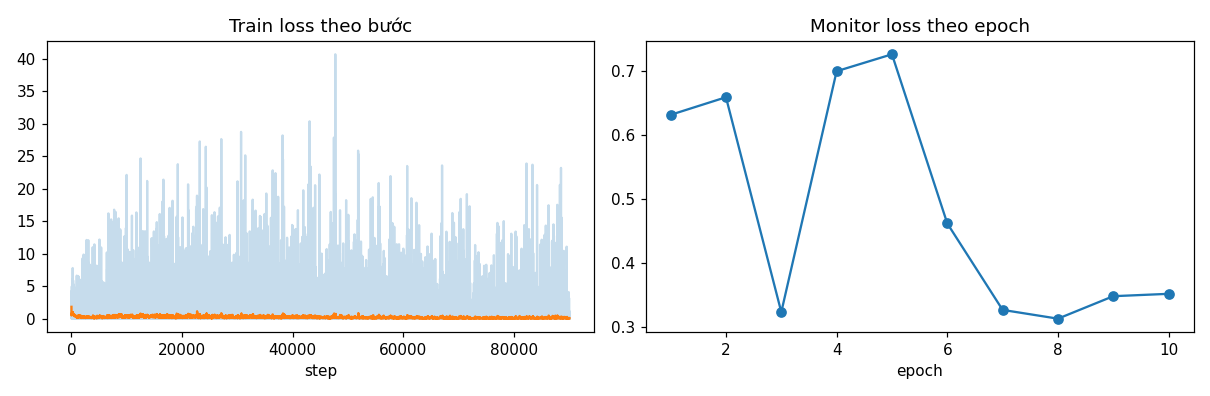

# Báo cáo fine-tuning UniFashion (bản tối thiểu)

- Trạng thái: completed
- Tiến độ: 10/10 epoch, 90000 cập nhật tối ưu
- Loss huấn luyện gần nhất: 0.0492 (TB 100 bước cuối)
- Monitor loss tốt nhất: 0.3129 (epoch 8)

| epoch | train_loss | monitor_loss |
|---|---|---|
| 1 | 0.3047 | 0.6317 |
| 2 | 0.3572 | 0.6592 |
| 3 | 0.3253 | 0.3232 |
| 4 | 0.2887 | 0.6998 |
| 5 | 0.2653 | 0.7263 |
| 6 | 0.2034 | 0.4618 |
| 7 | 0.1698 | 0.3266 |
| 8 | 0.1337 | 0.3129 |
| 9 | 0.1030 | 0.3480 |
| 10 | 0.1310 | 0.3517 |

Lưu ý: monitor loss là loss trên tập cố định, KHÔNG phải Recall@K.

In [ ]:
if (OUTPUT / "status.json").is_file():
    print(json.dumps(read_status(), indent=2, ensure_ascii=False))
    run_live([sys.executable, "-B", PROJECT / "scripts/report_unifashion_finetune.py",
              "--run-dir", OUTPUT], cwd=PROJECT)
    from IPython.display import Image, Markdown, display
    if (OUTPUT / "training_curves.png").is_file():
        display(Image(filename=str(OUTPUT / "training_curves.png")))
    if (OUTPUT / "training_report.md").is_file():
        display(Markdown((OUTPUT / "training_report.md").read_text(encoding="utf-8")))
else:
    print("Chưa có lần train nào tại", OUTPUT)

## **8 — Kiểm tra script đánh giá**

In [ ]:
r = subprocess.run([
    "python",
    str(PROJECT / "scripts/evaluate_unifashion_fashioniq.py"),
    "--help"
], cwd=PROJECT)
if r.returncode != 0 and TRAIN_ENABLED:
    raise RuntimeError("evaluate --help thất bại.")
print("Lưu ý: cell này chỉ kiểm tra --help; chưa chạy đánh giá Recall@K.")

Lưu ý: cell này chỉ kiểm tra --help; chưa chạy đánh giá Recall@K.
